In [71]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080314 

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp02_env
[学号] 20244080314
[机器指纹] 71540edf6c2a7b53
[RUN_ID] 20244080314-71540edf6c2a7b53


实验1：NumPy数组、数据类型与索引

In [72]:
import numpy as np

#分别创建整数、浮点数和布尔值 ndarray
arr_int = np.array([1, 2, 3])
arr_float = np.array([1.0, 2.0, 3.0])
arr_bool = np.array([True, False, True])

for name, arr in zip(["整数", "浮点数", "布尔值"], [arr_int, arr_float, arr_bool]):
    print(f"{name}数组: dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")

整数数组: dtype=int64, shape=(3,), ndim=1
浮点数数组: dtype=float64, shape=(3,), ndim=1
布尔值数组: dtype=bool, shape=(3,), ndim=1


In [73]:
#创建数组后改变形状
arr_1d = np.arange(12)
print("原数组:", arr_1d)
arr_3x4 = arr_1d.reshape(3, 4)
print("\n(3, 4) 形状:\n", arr_3x4)
arr_2x3x2 = arr_1d.reshape(2, 3, 2)
print("\n(2, 3, 2) 形状:\n", arr_2x3x2)

原数组: [ 0  1  2  3  4  5  6  7  8  9 10 11]

(3, 4) 形状:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

(2, 3, 2) 形状:
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


改变形状的条件： 改变形状时，原数组的元素总数必须等于新形状各个维度的乘积（即 12 = 3×4 = 2×3×2），否则会报错。

In [74]:
#对形状为 (3, 4) 的数组完成索引
print("取第2行:", arr_3x4[1], "形状:", arr_3x4[1].shape)
print("取第1至第3列:\n", arr_3x4[:, 0:3], "形状:", arr_3x4[:, 0:3].shape)
print("取大于6的元素:", arr_3x4[arr_3x4 > 6], "形状:", arr_3x4[arr_3x4 > 6].shape)

取第2行: [4 5 6 7] 形状: (4,)
取第1至第3列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 形状: (3, 3)
取大于6的元素: [ 7  8  9 10 11] 形状: (5,)


In [75]:
#使⽤ np.arange(10)选出元素
arr_10 = np.arange(10)
print("小于2或大于7:", arr_10[(arr_10 < 2) | (arr_10 > 7)])
print("大于3且小于7:", arr_10[(arr_10 > 3) & (arr_10 < 7)])
print("使用 np.logical_or:", arr_10[np.logical_or(arr_10 < 2, arr_10 > 7)])
print("使用 np.logical_and:", arr_10[np.logical_and(arr_10 > 3, arr_10 < 7)])

小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]
使用 np.logical_or: [0 1 8 9]
使用 np.logical_and: [4 5 6]


In [76]:
#逐元素乘法与矩阵乘法
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A * B (逐元素乘法):\n", A * B)
print("np.multiply (逐元素乘法):\n", np.multiply(A, B))
print("A @ B (矩阵乘法):\n", A @ B)
print("np.matmul (矩阵乘法):\n", np.matmul(A, B))

A * B (逐元素乘法):
 [[ 5 12]
 [21 32]]
np.multiply (逐元素乘法):
 [[ 5 12]
 [21 32]]
A @ B (矩阵乘法):
 [[19 22]
 [43 50]]
np.matmul (矩阵乘法):
 [[19 22]
 [43 50]]


*和np.multiply() 为逐元素相乘（对应位置的元素相乘）；@和np.matmul()为矩阵乘法（行乘列求和相加）

实验2：随机抽样、统计与缺失值

In [77]:
#设置固定种子
rng = np.random.default_rng(42)

#模拟成绩
scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print(f"样本数: {scores.size}")
print(f"最小值: {scores.min():.2f}, 最大值: {scores.max():.2f}")
print(f"均值: {scores.mean():.2f}, 标准差: {scores.std():.2f}")
print(f"极差: {np.ptp(scores):.2f}")

样本数: 1000
最小值: 33.52, 最大值: 100.00
均值: 69.71, 标准差: 9.88
极差: 66.48


In [78]:
arr_1_to_10 = np.arange(1, 11)
# 均匀抽样
uniform_sample = rng.choice(arr_1_to_10, size=5, replace=False)
print("均匀抽样:", uniform_sample)

# 按整数大小成比例加权抽样
p = arr_1_to_10 / arr_1_to_10.sum()
weighted_sample = rng.choice(arr_1_to_10, size=5, replace=False, p=p)
print("加权抽样:", weighted_sample)

均匀抽样: [7 2 9 5 4]
加权抽样: [3 9 2 6 5]


In [79]:
#随机排列与原地打乱
orig_arr = np.arange(6)
print("原数组:", orig_arr)

#返回新数组
permuted_arr = rng.permutation(orig_arr)
print("原数组不变:", orig_arr)
print("新数组:", permuted_arr)

#原地打乱
shuffled_arr = orig_arr.copy()
rng.shuffle(shuffled_arr)
print("原地打乱:", shuffled_arr)

原数组: [0 1 2 3 4 5]
原数组不变: [0 1 2 3 4 5]
新数组: [0 1 2 4 3 5]
原地打乱: [1 3 2 4 0 5]


In [80]:
#缺失值
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan #第10、20、30个值设为nan

print("普通均值:", np.mean(scores_nan))
print("忽略缺失值均值:", np.nanmean(scores_nan))
print("缺失值个数:", np.isnan(scores_nan).sum())

普通均值: nan
忽略缺失值均值: 69.71315691233939
缺失值个数: 3


np.nan为缺失值。普通的统计函数遇到nan时会直接返回nan；所以得使用忽略缺失值函数，比如说np.nanmean才能算出有效均值。

In [81]:
import pandas as pd
#整理成内存表格变量
score_table = pd.DataFrame({
    "Index": np.arange(1, 1001),
    "Score": scores_nan
})
#查看下数据
display(score_table.head())

,Index,Score
0,1,73.047171
1,2,59.600159
2,3,77.504512
3,4,79.405647
4,5,50.489648


实验3：SciPy数值计算与Matplotlib可视化

In [82]:
from scipy.linalg import solve
#解线性方程组
A_eq = np.array([[3, 1], [1, 2]])
b_eq = np.array([9, 8])
sol = solve(A_eq, b_eq)
print("解为(x, y):", sol)
print("代入验证A @ sol:", A_eq @ sol)

解为(x, y): [2. 3.]
代入验证A @ sol: [9. 8.]


In [83]:
from scipy.optimize import root
#求根 
def f_root(x):
    return x**2 - 2

res_pos = root(f_root, x0=1.0)
res_neg = root(f_root, x0=-1.0)

print(f"正根: 成功={res_pos.success}, 结果={res_pos.x[0]:.6f}, 函数值={f_root(res_pos.x[0]):.2e}")
print(f"负根: 成功={res_neg.success}, 结果={res_neg.x[0]:.6f}, 函数值={f_root(res_neg.x[0]):.2e}")

正根: 成功=True, 结果=1.414214, 函数值=-8.88e-16
负根: 成功=True, 结果=-1.414214, 函数值=-8.88e-16


In [84]:
from scipy.optimize import minimize
#极小值
def f_min(x):
    return x**2 + x + 2

res_min = minimize(f_min, x0=0.0)
print(f"极小值点 x = {res_min.x[0]:.4f}")
print(f"极小值 f(x) = {res_min.fun:.4f}")
print("解析对比: x=-0.5, f(x)=1.75")

极小值点 x = -0.5000
极小值 f(x) = 1.7500
解析对比: x=-0.5, f(x)=1.75


In [85]:
from scipy.stats import ttest_ind
#t检验
rng_t = np.random.default_rng(2024)
group1 = rng_t.normal(loc=0, scale=1, size=100)
group2 = rng_t.normal(loc=1, scale=1, size=100)

t_stat, p_val = ttest_ind(group1, group2)
print(f"t统计量: {t_stat:.4f}, p值: {p_val:.4e}")
if p_val < 0.05:
    print("结论: p < 0.05,拒绝原假设，两组存在显著差异。")
else:
    print("结论: p >= 0.05,无法拒绝原假设，两组无显著差异。")

t统计量: -5.5665, p值: 8.3781e-08
结论: p < 0.05,拒绝原假设，两组存在显著差异。


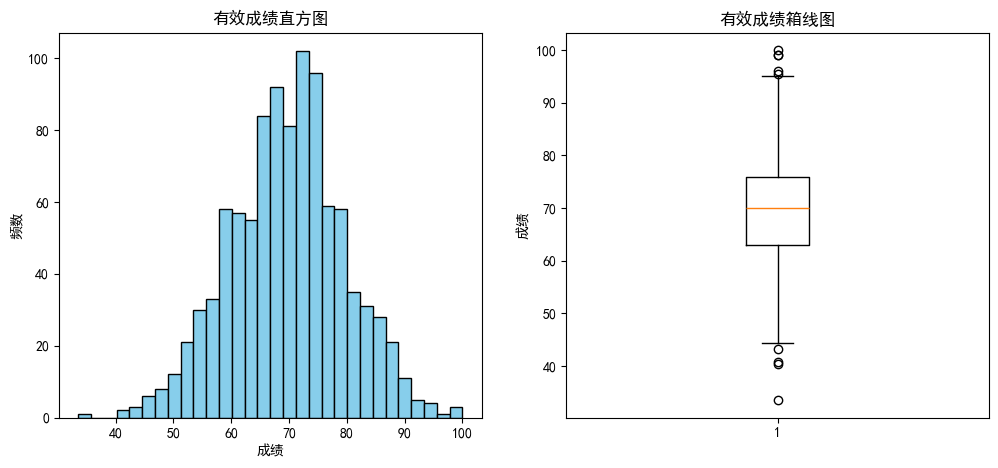

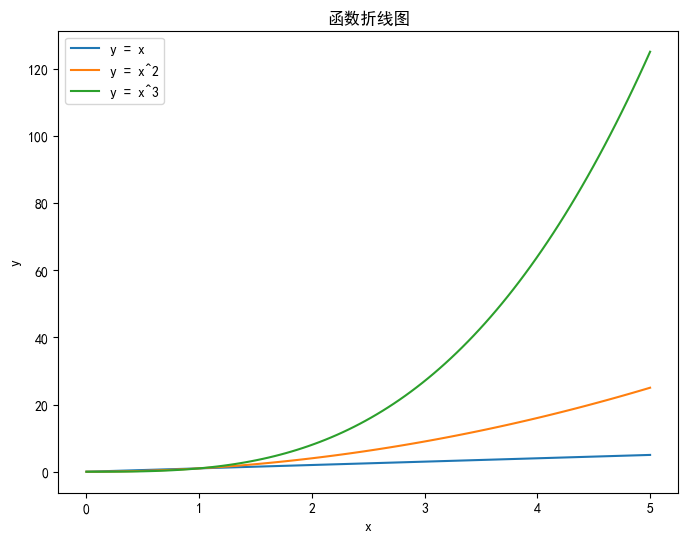

In [86]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

#过滤nan值
valid_scores = scores_nan[~np.isnan(scores_nan)]

#图1：直方图
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(valid_scores, bins=30, color='skyblue', edgecolor='black')
axes[0].set_title("有效成绩直方图")
axes[0].set_xlabel("成绩")
axes[0].set_ylabel("频数")

#箱线图
axes[1].boxplot(valid_scores)
axes[1].set_title("有效成绩箱线图")
axes[1].set_ylabel("成绩")
plt.show()

#图2：折线图
x = np.linspace(0, 5, 100)
plt.figure(figsize=(8, 6))
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x^2")
plt.plot(x, x**3, label="y = x^3")
plt.title("函数折线图")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

实验4：pandas Series、DataFrame 与内存中的CSV读写

In [87]:
#创建DataFrame
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("\n前3行:\n", df.head(3))
print("\n基本统计信息:\n", df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [88]:
#分别用loc和iloc读取与筛选
print("loc读取Carol:\n", df.loc["Carol"])
print("\niloc读取第3行(索引2):\n", df.iloc[2])
print("\n平均分>=80的学生:\n", df[df["Average"] >= 80])

loc读取Carol:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc读取第3行(索引2):
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分>=80的学生:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [89]:
#列均值和行均值
print("列均值 (axis=0):\n", df[["Math", "English", "Python"]].mean(axis=0))
print("\n行均值 (axis=1):\n", df[["Math", "English", "Python"]].mean(axis=1))

列均值 (axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

行均值 (axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [90]:
#apply()计算最高分
df["Max_Score"] = df[["Math", "English", "Python"]].apply(np.max, axis=1)
print("每人最高分:\n", df["Max_Score"])

#agg()得到最小值、均值和最大值
print("\nagg 统计:\n", df[["Math", "English", "Python"]].agg(["min", "mean", "max"]))

#rank()进行排名
df["Math_Rank"] = df["Math"].rank(ascending=False)
print("\n数学排名:\n", df["Math_Rank"])

每人最高分:
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: Max_Score, dtype: int64

agg 统计:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

数学排名:
 Name
Alice    2.0
Bob      5.0
Carol    1.0
David    6.0
Eva      4.0
Frank    3.0
Name: Math_Rank, dtype: float64


In [91]:
#进行分组统计和transform
print("每组人数:\n", df.groupby("Group").size())
print("\n每组三科平均分:\n", df.groupby("Group")[["Math", "English", "Python"]].mean())

df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加所在组 Python 平均分后:\n", df[["Group", "Python", "Group_Python_Mean"]])

每组人数:
 Group
A    3
B    3
dtype: int64

每组三科平均分:
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

增加所在组 Python 平均分后:
       Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [92]:
#⽤ filter()保留Python平均分不低于80的组
kept_groups = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("Python平均分>=80的组员:\n", kept_groups)

Python平均分>=80的组员:
       Group  Math  English  Python  Total    Average  Max_Score  Math_Rank  \
Name                                                                         
Alice     A    88       90      95    273  91.000000         95        2.0   
Bob       A    72       68      80    220  73.333333         80        5.0   
Carol     B    91       85      89    265  88.333333         91        1.0   
David     B    65       73      70    208  69.333333         73        6.0   
Eva       A    79       92      86    257  85.666667         92        4.0   
Frank     B    84       77      82    243  81.000000         84        3.0   

       Group_Python_Mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


In [93]:
#协方差矩阵和相关系数矩阵
subjects = df[["Math", "English", "Python"]]
print("协方差矩阵:\n", subjects.cov())
print("\n皮尔森相关系数矩阵:\n", subjects.corr())

协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔森相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


以Math和Python为例，根据输出的结果，它们之间的协方差结果为正数，说明两者呈同向变化，就是数学成绩高的，Python成绩往往也高；相关系数越接近1或者是-1，说明线性相关性越强，如果接近0，则说明线性相关性弱。